In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, log_loss

In [4]:
file_path = "/home/patel-krish/anaconda3/BrainyBeam/heart.csv"

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop("target", axis=1)
y = df["target"]

X = X.apply(pd.to_numeric, errors="coerce")

imputer = SimpleImputer(strategy="median")
X = imputer.fit_transform(X)

y = np.array(y).astype(int)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [7]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
b2 = np.zeros((1, output_size))

In [8]:
def relu(x):
    return np.maximum(0, x)


def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

In [9]:
def forward(X):
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    return Z1, A1, A2

In [10]:
learning_rate = 0.01
minimum_lr = 0.0001
lr_factor = 0.5
patience = 5
tolerance = 0.0001

best_val_loss = float("inf")
wait = 0

In [15]:
epochs = 200
batch_size = 32

train_losses = []
val_losses = []
learning_rates = []

best_weights = None
best_epoch = 0
early_stop_patience = 15
early_stop_wait = 0

for epoch in range(epochs):

    indices = np.random.permutation(len(X_train))
    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train[indices]

    for start in range(0, len(X_train), batch_size):

        end = start + batch_size

        X_batch = X_train_shuffled[start:end]
        y_batch = y_train_shuffled[start:end].reshape(-1, 1)

        Z1, A1, A2 = forward(X_batch)

        m = len(X_batch)

        dZ2 = A2 - y_batch

        dW2 = np.dot(A1.T, dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        dA1 = np.dot(dZ2, W2.T)
        dZ1 = dA1 * (Z1 > 0)

        dW1 = np.dot(X_batch.T, dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        gradients = [dW1, db1, dW2, db2]

        gradient_norm = np.sqrt(
            sum(np.sum(g ** 2) for g in gradients)
        )

        max_gradient_norm = 5.0

        if gradient_norm > max_gradient_norm:
            scale = max_gradient_norm / (gradient_norm + 1e-8)
            dW1 *= scale
            db1 *= scale
            dW2 *= scale
            db2 *= scale

        # Update weights
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

   

    _, _, train_predictions = forward(X_train)
    _, _, val_predictions = forward(X_val)

    train_loss = log_loss(
        y_train,
        train_predictions.ravel(),
        labels=[0, 1]
    )

    val_loss = log_loss(
        y_val,
        val_predictions.ravel(),
        labels=[0, 1]
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    learning_rates.append(learning_rate)


    if val_loss < best_val_loss - tolerance:

        best_val_loss = val_loss
        wait = 0
        early_stop_wait = 0
        best_epoch = epoch + 1

        best_weights = (
            W1.copy(),
            b1.copy(),
            W2.copy(),
            b2.copy()
        )

    else:
        wait += 1
        early_stop_wait += 1

    if wait >= patience:

        new_lr = max(
            learning_rate * lr_factor,
            minimum_lr
        )

        if new_lr < learning_rate:
            learning_rate = new_lr

            print(
                f"Epoch {epoch + 1}: "
                f"Learning rate reduced to {learning_rate:.6f}"
            )

        wait = 0

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Learning Rate: {learning_rate:.6f}"
    )

    # Early stopping
    if early_stop_wait >= early_stop_patience:
        print("Early stopping triggered.")
        break



Epoch 1/200 | Train Loss: 0.2748 | Validation Loss: 0.5818 | Learning Rate: 0.010000
Epoch 2/200 | Train Loss: 0.2744 | Validation Loss: 0.5819 | Learning Rate: 0.010000
Epoch 3/200 | Train Loss: 0.2740 | Validation Loss: 0.5820 | Learning Rate: 0.010000
Epoch 4/200 | Train Loss: 0.2736 | Validation Loss: 0.5821 | Learning Rate: 0.010000
Epoch 5/200 | Train Loss: 0.2732 | Validation Loss: 0.5821 | Learning Rate: 0.010000
Epoch 6: Learning rate reduced to 0.005000
Epoch 6/200 | Train Loss: 0.2727 | Validation Loss: 0.5822 | Learning Rate: 0.005000
Epoch 7/200 | Train Loss: 0.2725 | Validation Loss: 0.5822 | Learning Rate: 0.005000
Epoch 8/200 | Train Loss: 0.2724 | Validation Loss: 0.5823 | Learning Rate: 0.005000
Epoch 9/200 | Train Loss: 0.2722 | Validation Loss: 0.5823 | Learning Rate: 0.005000
Epoch 10/200 | Train Loss: 0.2720 | Validation Loss: 0.5823 | Learning Rate: 0.005000
Epoch 11: Learning rate reduced to 0.002500
Epoch 11/200 | Train Loss: 0.2718 | Validation Loss: 0.5824 | 

In [16]:


if best_weights is not None:
    W1, b1, W2, b2 = best_weights

In [17]:

_, _, test_predictions = forward(X_test)

predicted_classes = (
    test_predictions.ravel() >= 0.5
).astype(int)

accuracy = accuracy_score(
    y_test,
    predicted_classes
)

print("\nFinal Model Results")
print("-------------------")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", round(best_val_loss, 4))
print("Final Learning Rate:", round(learning_rate, 6))
print("Test Accuracy:", round(accuracy, 4))


Final Model Results
-------------------
Best Epoch: 1
Best Validation Loss: 0.5818
Final Learning Rate: 0.00125
Test Accuracy: 0.7377


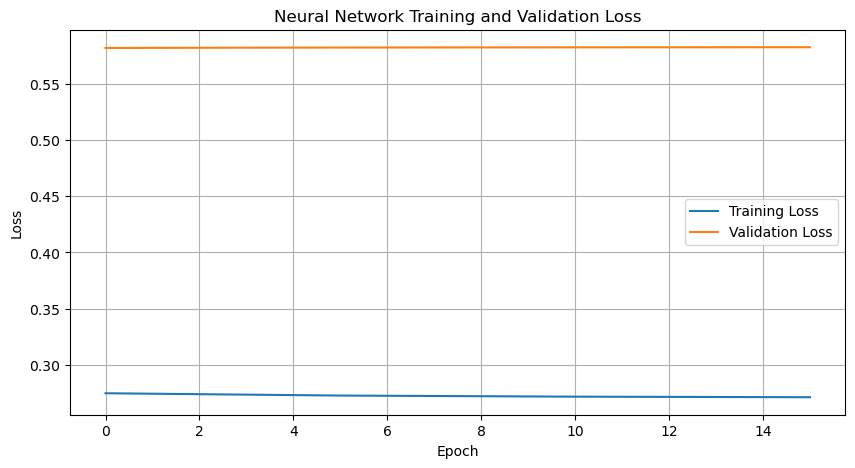

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Neural Network Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

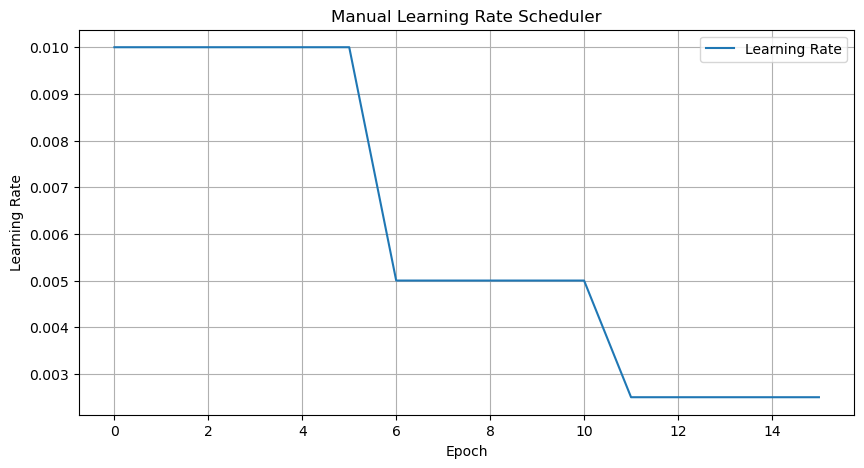

In [19]:


plt.figure(figsize=(10, 5))

plt.plot(learning_rates, label="Learning Rate")

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Manual Learning Rate Scheduler")
plt.legend()
plt.grid(True)
plt.show()
